
## Data Matching Notebook

I currently have two datasets from kaggle

### Top 850 Chords

This is a kaggle dataset sourced from Ultimate Guitar.
Since my project is mainly targetting difficulty and factors of that, I will only need difficulty, capo, and key

### Chords & Lyrics

This is another kaggle dataset sourced from e-chords
Although they come from different sources, I did check the difficulty of the matched songs and the majority are the same
This dataset will be used for its list of chords

### Jupyter Notebook Overview
In this Jupyter Notebook I will be trying to combine these two notebooks. They will be matched by song name.
While I am cleaning and combining the datasets, I will look at the distributions of certain categories to see if they are necessary

In [1078]:
import numpy as np
import pandas as pd
import os
import kagglehub
from kagglehub import KaggleDatasetAdapter



### Loading in the first dataset: Top 850 Guitar tabs


In [1079]:
path = kagglehub.dataset_download("thomaskonstantin/top-850-guitar-tabs")
print("Folder:", path)
print("Exists:", os.path.exists(path))
print("Contents:", os.listdir(path))

csv_name = os.listdir(path)[0]
top850 = pd.read_csv(os.path.join(path, csv_name))

top850.head()

Folder: C:\Users\TiffB\.cache\kagglehub\datasets\thomaskonstantin\top-850-guitar-tabs\versions\1
Exists: True
Contents: ['gutiarDB.csv']


,Artist,Song Name,Song Rating,Song Hits,Page Type,Difficulty,Key,Capo,Tuning
0,Jeff Buckley,Hallelujah,"40,045","31,174,526",Chords,novice,Db,1st fret,E A D G B E
1,Ed Sheeran,Perfect,"31,694","25,794,778",Chords,novice,Ab,1st fret,E A D G B E
2,John Legend,All Of Me,"20,169","25,653,362",Chords,novice,Fm,1st fret,E A D G B E
3,Passenger,Let Her Go,"17,267","24,556,593",Chords,novice,Em,7th fret,E A D G B E
4,Led Zeppelin,Stairway To Heaven,"11,839","20,762,763",Tab,intermediate,Am,No Capo,E A D G B E


As you can see this includes Difficulty, Key, Capo, and Tuning. All of which are going to be used to predict the difficulty. The columns Song Rating and Song Hits are not necessary for my project so I am going to drop those columns

In [1080]:
top850 = top850.drop(columns = ["Song Rating", "Song Hits"])
top850

,Artist,Song Name,Page Type,Difficulty,Key,Capo,Tuning
0,Jeff Buckley,Hallelujah,Chords,novice,Db,1st fret,E A D G B E
1,Ed Sheeran,Perfect,Chords,novice,Ab,1st fret,E A D G B E
2,John Legend,All Of Me,Chords,novice,Fm,1st fret,E A D G B E
3,Passenger,Let Her Go,Chords,novice,Em,7th fret,E A D G B E
4,Led Zeppelin,Stairway To Heaven,Tab,intermediate,Am,No Capo,E A D G B E
...,...,...,...,...,...,...,...
845,ZZ Top,Beer Drinkers And Hell Raisers,Chords,intermediate,Db,No Capo,E A D G B E
846,Weezer,Weezer Album,Tab,intermediate,Db,No Capo,E A D G B E
847,Misc Soundtrack,Mission Impossible 2 - Nyah,Tab,intermediate,Db,No Capo,E A D G B
848,Radiohead,Fake Plastic Trees,Chords,intermediate,A,No Capo,E A D G B E


To be able to match the artists/titles to the other dataset I will need the format to be consistent, so I am going to make the characters of the string lower.

In [1081]:
top850["Artist"] = top850["Artist"].str.lower().str.strip()
top850["Song Name"] = top850["Song Name"].str.lower().str.strip()
top850

,Artist,Song Name,Page Type,Difficulty,Key,Capo,Tuning
0,jeff buckley,hallelujah,Chords,novice,Db,1st fret,E A D G B E
1,ed sheeran,perfect,Chords,novice,Ab,1st fret,E A D G B E
2,john legend,all of me,Chords,novice,Fm,1st fret,E A D G B E
3,passenger,let her go,Chords,novice,Em,7th fret,E A D G B E
4,led zeppelin,stairway to heaven,Tab,intermediate,Am,No Capo,E A D G B E
...,...,...,...,...,...,...,...
845,zz top,beer drinkers and hell raisers,Chords,intermediate,Db,No Capo,E A D G B E
846,weezer,weezer album,Tab,intermediate,Db,No Capo,E A D G B E
847,misc soundtrack,mission impossible 2 - nyah,Tab,intermediate,Db,No Capo,E A D G B
848,radiohead,fake plastic trees,Chords,intermediate,A,No Capo,E A D G B E


In [1082]:
top850['Page Type'].unique()

<StringArray>
['Chords', 'Tab', 'Ukulele', 'Bass', 'Guitar Pro']
Length: 5, dtype: str

This dataset contains too many types of pages. Since our project is only based on the chords of a song, we will only include that Page Type.

In [1083]:
top850 = top850[top850["Page Type"] == "Chords"]
top850["Page Type"].unique()

<StringArray>
['Chords']
Length: 1, dtype: str

Now that all the page types are the same we can drop this column

In [1084]:
top850.drop(columns="Page Type")

,Artist,Song Name,Difficulty,Key,Capo,Tuning
0,jeff buckley,hallelujah,novice,Db,1st fret,E A D G B E
1,ed sheeran,perfect,novice,Ab,1st fret,E A D G B E
2,john legend,all of me,novice,Fm,1st fret,E A D G B E
3,passenger,let her go,novice,Em,7th fret,E A D G B E
5,jason mraz,im yours,novice,B,4th fret,E A D G B E
...,...,...,...,...,...,...
841,elton john,your song,intermediate,Db,1st fre,E A D G B E
843,naif,benci untuk mencinta,intermediate,D,No Capo,E A D G B E
844,katy perry,teenage dream,intermediate,Db,3rd fre,E A D G B E
845,zz top,beer drinkers and hell raisers,intermediate,Db,No Capo,E A D G B E


In [1085]:
top850["Difficulty"].unique()


<StringArray>
['novice', 'intermediate', 'intermediat', 'advanced', 'novic']
Length: 5, dtype: str

Difficulty has some values that aren't spelled correctly. It also has a small number of advanced values. Must make intermediat=intermediate and novic=novice.

In [1086]:
top850["Difficulty"] = top850["Difficulty"].replace({
    "novic": "beginner",
    "novice": "beginner",
    "intermediat": "intermediate",
})
top850["Difficulty"].unique()

<StringArray>
['beginner', 'intermediate', 'advanced']
Length: 3, dtype: str

In [1087]:
# since this is what will be predicted, lets look at the counts of each value
top850['Difficulty'].value_counts(dropna=False)

Difficulty
intermediate    362
beginner        317
advanced          1
Name: count, dtype: int64

The advanced row only has 1 item. So I am going to drop that option since it will not contribute to the prediction very well. Luckily the distribution between intermediate and beginner is around ~50/~50

In [1088]:
top850 = top850[top850["Difficulty"] != "advanced"]
top850


,Artist,Song Name,Page Type,Difficulty,Key,Capo,Tuning
0,jeff buckley,hallelujah,Chords,beginner,Db,1st fret,E A D G B E
1,ed sheeran,perfect,Chords,beginner,Ab,1st fret,E A D G B E
2,john legend,all of me,Chords,beginner,Fm,1st fret,E A D G B E
3,passenger,let her go,Chords,beginner,Em,7th fret,E A D G B E
5,jason mraz,im yours,Chords,beginner,B,4th fret,E A D G B E
...,...,...,...,...,...,...,...
841,elton john,your song,Chords,intermediate,Db,1st fre,E A D G B E
843,naif,benci untuk mencinta,Chords,intermediate,D,No Capo,E A D G B E
844,katy perry,teenage dream,Chords,intermediate,Db,3rd fre,E A D G B E
845,zz top,beer drinkers and hell raisers,Chords,intermediate,Db,No Capo,E A D G B E


Nest is the key, everything seems fine with this, I'm just curious how many different options there are

In [1089]:
print(top850["Key"].unique())
print(top850["Key"].value_counts(dropna=False))
# This is a decent distribution I believe

<StringArray>
[ ' Db',  ' Ab',  ' Fm',  ' Em',   ' B',   ' C',   ' D',  ' Bm',   ' A',
   ' E', ' Bbm',   ' G', ' F#m',   ' F',   'Db',  ' Am',  ' Cm',  ' F#',
  ' Eb',  ' Dm',  ' C#', ' C#m',  ' Bb',  ' Gm', ' Ebm', ' G#m',  ' Gb',
 ' Abm', ' A#m']
Length: 29, dtype: str
Key
Db      151
 C       87
 G       81
 D       48
 Am      39
 A       38
 Em      36
 F       32
 E       20
 Bm      17
 B       15
 Dm      15
 Eb      12
 F#m     11
 Db      10
 Cm       9
 Bb       9
 Ab       8
 Bbm      7
 C#m      7
 Fm       6
 Gm       5
 Ebm      5
 F#       3
 C#       2
 Gb       2
 Abm      2
 G#m      1
 A#m      1
Name: count, dtype: int64


I want to convert the Capo strings into 0-12 integers

In [1090]:
print(top850["Capo"].value_counts(dropna=False))
top850["Capo"] = top850["Capo"].replace("No Capo", 0)



Capo
No Capo      391
 1st fret     56
 2nd fret     55
 3rd fret     49
 4th fret     32
 5th fret     16
 3rd fre      16
 4th fre      15
 2nd fre      12
 1st fre      12
 6th fret      9
 7th fret      5
 5th fre       4
 7th fre       3
 8th fret      2
 6th fre       2
Name: count, dtype: int64


In [1091]:
#match the number with the first character in each string
top850["Capo"] = np.where(top850["Capo"] != 0, top850["Capo"].str[1], top850["Capo"])
top850["Capo"] = top850["Capo"].astype(int)
top850

,Artist,Song Name,Page Type,Difficulty,Key,Capo,Tuning
0,jeff buckley,hallelujah,Chords,beginner,Db,1,E A D G B E
1,ed sheeran,perfect,Chords,beginner,Ab,1,E A D G B E
2,john legend,all of me,Chords,beginner,Fm,1,E A D G B E
3,passenger,let her go,Chords,beginner,Em,7,E A D G B E
5,jason mraz,im yours,Chords,beginner,B,4,E A D G B E
...,...,...,...,...,...,...,...
841,elton john,your song,Chords,intermediate,Db,1,E A D G B E
843,naif,benci untuk mencinta,Chords,intermediate,D,0,E A D G B E
844,katy perry,teenage dream,Chords,intermediate,Db,3,E A D G B E
845,zz top,beer drinkers and hell raisers,Chords,intermediate,Db,0,E A D G B E


In [1092]:
top850["Tuning"].value_counts()

Tuning
 E A D G B E          548
 E A D G B             60
E A D G B E            50
 Eb Ab Db Gb Bb Eb     15
 Eb Ab Db Gb Bb E       2
 D G C F A              2
 C# F# B E G# C#        1
 D A D G B              1
Name: count, dtype: int64

I actually going to drop this column because ~96% of the tunings are in standard tuning and some of the foramtting is really wonky. I think it would be too much effort for very little results

In [1093]:
top850 = top850.drop(columns="Tuning")
top850 = top850.drop(columns="Page Type")
top850

,Artist,Song Name,Difficulty,Key,Capo
0,jeff buckley,hallelujah,beginner,Db,1
1,ed sheeran,perfect,beginner,Ab,1
2,john legend,all of me,beginner,Fm,1
3,passenger,let her go,beginner,Em,7
5,jason mraz,im yours,beginner,B,4
...,...,...,...,...,...
841,elton john,your song,intermediate,Db,1
843,naif,benci untuk mencinta,intermediate,D,0
844,katy perry,teenage dream,intermediate,Db,3
845,zz top,beer drinkers and hell raisers,intermediate,Db,0


### Chords and Lyrics Dataset
This dataset will be mainly sourced for its chords.
My first job is to combine the two datasets together, by artist and name
Afterward I need to reformat the chords column because fromt the preview I noticed the format is unorganized

In [1094]:
path = kagglehub.dataset_download("eitanbentora/chords-and-lyrics-dataset")
print("Folder:", path)
print("Exists:", os.path.exists(path))
print("Contents:", os.listdir(path))

csv_name = os.listdir(path)[0]
chords_and_lyrics = pd.read_csv(os.path.join(path, csv_name))

chords_and_lyrics = chords_and_lyrics.drop_duplicates()

Folder: C:\Users\TiffB\.cache\kagglehub\datasets\eitanbentora\chords-and-lyrics-dataset\versions\1
Exists: True
Contents: ['chords_and_lyrics.csv', 'chords_and_lyrics.pkl']


In [1095]:
# seeing if any of the songs match eachother
chords_and_lyrics["song_name"] = chords_and_lyrics["song_name"].str.lower().str.strip()
chords_and_lyrics["artist_name"] = chords_and_lyrics["artist_name"].str.lower().str.strip()

left_cols = ["Song Name", "Artist"]
right_cols = ["song_name", "artist_name"]

test_matched = top850.merge(chords_and_lyrics, left_on=left_cols, right_on=right_cols, how='inner')
test_matched

,Artist,Song Name,Difficulty,Key,Capo,Unnamed: 0,artist_name,song_name,chords&lyrics,chords,lyrics,tabs,lang,artist_id,followers,genres,popularity,name_e_chords
0,ed sheeran,perfect,beginner,Ab,1,1027,ed sheeran,perfect,\nCapo on 1st fret\n\t \t\t \r\n\r\nIntr...,"{2: 'Intro: G ', 5: ' G E...","{0: '\nCapo on 1st fret\n\t \t\t ', 1: '...",{},en,6eUKZXaKkcviH0Ku9w2n3V,78900234.0,"['pop', 'uk pop']",92,ed-sheeran
1,john legend,all of me,beginner,Fm,1,6898,john legend,all of me,\n\t \t\thide this tab Intro: Fm Db Ab Eb (x2...,{0: '\n\t \t\thide this tab Intro: Fm Db Ab E...,"{1: '', 3: 'What would I do, without your smar...",{},en,5y2Xq6xcjJb2jVM54GHK3t,5610565.0,"['neo soul', 'pop', 'pop soul', 'r&b', 'urban ...",83,john-legend
2,passenger,let her go,beginner,Em,7,18248,passenger,let her go,\nCapo on 7th fret\n\t \t\t \r\n\r\n\r\n\r...,{8: ' F G ...,"{0: '\nCapo on 7th fret\n\t \t\t ', 1: '',...","{5: 'hide this tab Intro: ', 10: 'e|-----0...",en,0gadJ2b9A4SKsB1RFkBb66,2766259.0,"['folk-pop', 'neo mellow', 'pop', 'pop rock']",77,passenger
3,ed sheeran,thinking out loud,beginner,D,2,1073,ed sheeran,thinking out loud,\n\t \t\t\r\nD D/F# \r\n When your legs...,"{1: 'D D/F# ', 3: ' G ...","{0: '\n\t \t\t', 2: "" When your legs don't w...",{},en,6eUKZXaKkcviH0Ku9w2n3V,78900234.0,"['pop', 'uk pop']",92,ed-sheeran
4,coldplay,the scientist,beginner,Bm,3,2529,coldplay,the scientist,\n\t \t\tIntro: Dm Bb F C/E x2 \r\n\r\nVerse...,"{0: '\n\t \t\tIntro: Dm Bb F C/E x2 ', 3: 'D...","{1: '', 2: 'Verse 1: ', 4: ""Come up to meet ...",{},en,4gzpq5DPGxSnKTe4SA8HAU,29753797.0,"['permanent wave', 'pop']",89,coldplay
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
499,elton john,your song,intermediate,Db,1,4696,elton john,your song,\nCapo on 3rd fret\n\t \t\t\r\n \r\n\r\nIntro...,"{3: 'Intro ', 5: 'C F G F ', 9: 'C ...","{0: '\nCapo on 3rd fret\n\t \t\t', 1: ' ', 2:...",{},en,3PhoLpVuITZKcymswpck5b,6915079.0,"['glam rock', 'mellow gold', 'piano rock', 'so...",85,elton-john
500,naif,benci untuk mencinta,intermediate,D,0,97558,naif,benci untuk mencinta,\n\t \t\t\r\n\r\nIntro: D Dm7 D7 G Gm F#m A A...,"{2: 'Intro: D Dm7 D7 G Gm F#m A A7 ', 4: 'D ...","{0: '\n\t \t\t', 1: '', 3: '', 5: 'oh.. betap...",{},id,57A85GCAJn0reNAez6Hswt,415238.0,"['indonesian indie', 'indonesian pop']",58,naif
501,katy perry,teenage dream,intermediate,Db,3,127128,katy perry,teenage dream,\n\t \t\tD# F \r\n Yo...,"{0: '\n\t \t\tD# F ',...","{1: "" You think I'm pretty, without any make-u...",{},en,6jJ0s89eD6GaHleKKya26X,18021998.0,"['dance pop', 'pop', 'post-teen pop']",87,katy-perry
502,zz top,beer drinkers and hell raisers,intermediate,Db,0,28343,zz top,beer drinkers and hell raisers,\n\t \t\tBeer Drinkers and Hell Raisers \r\n\...,{13: ' G (stop) ...,{0: '\n\t \t\tBeer Drinkers and Hell Raisers ...,{2: 'hide this tab Intro (G): |-------...,en,2AM4ilv6UzW0uMRuqKtDgN,2985004.0,"['album rock', 'blues rock', 'classic rock', '...",73,zz-top


In [1096]:
# ok lets look at how the distribution is between different columns
# difficulty: ~ 50/50 distribution good
test_matched["Difficulty"].value_counts()

# key: about the same distribution, the majority are Db but thats ok
test_matched["Key"].value_counts()

# Capo: about the same distribution, the majority are No capo but thats ok
test_matched["Capo"].value_counts()

combined = test_matched 

I'm going to start cleaning the combined dataset, focusing on the chords_and_lyrics
I don't need lyrics/tabs/lang/artist_id/followers/genres/popularity/name_e_chords

In [1097]:
combined = combined.drop(columns=["lyrics", "tabs", "lang", "artist_id", "followers", "genres", "popularity", "name_e_chords", "artist_name", "song_name", "chords&lyrics", "Unnamed: 0"])
combined.head()

,Artist,Song Name,Difficulty,Key,Capo,chords
0,ed sheeran,perfect,beginner,Ab,1,"{2: 'Intro: G ', 5: ' G E..."
1,john legend,all of me,beginner,Fm,1,{0: '\n\t \t\thide this tab Intro: Fm Db Ab E...
2,passenger,let her go,beginner,Em,7,{8: ' F G ...
3,ed sheeran,thinking out loud,beginner,D,2,"{1: 'D D/F# ', 3: ' G ..."
4,coldplay,the scientist,beginner,Bm,3,"{0: '\n\t \t\tIntro: Dm Bb F C/E x2 ', 3: 'D..."


Now theres a Couple of ways I want to format the chords:
It needs to be cleaned first but the extra columns I want to add are:
** Number of Bar Chords
** Number of Unique Chords
** Presence of most 7 most common chords

In [1098]:
# cleaning the chords
print(combined["chords"][0])
print(combined["chords"][40])
print(combined["chords"][101])
print(combined["chords"][300])



{2: 'Intro: G      ', 5: '          G        Em7      ', 7: '             C9                            D      ', 9: '               G           Em7      ', 11: '         C9                                    D      ', 15: '                                 G      ', 17: '             Em7                     C9                G  D      ', 19: '                   G                         Em7      ', 21: '            C9                   D      ', 24: '      Em7   C9             G          D              Em7      ', 26: 'C9                G     D                Em7      ', 28: '          C9                G                 D              Em7      ', 30: '         C9                G        D             G      ', 33: 'G  D/F#  Em7  D  C9  -  D  -        ', 36: '               G                    Em7      ', 38: '                C9                                        D      ', 40: '           G             Em7      ', 42: '         C9                              D      ', 46: '      


### characteristics of these rows

** It is a dictionary
** There are sporadic '' throughout
** occasionally there are numbers with colons folowing
** Some of them contain tableture denoted by "|------|"

what needs to gotten rid of
** the symbols
** .strip
** extra spaces between the letters
** convert into list

In [1099]:
# Get rid of characters: "}", ",","|", "'", 
combined["chords"] = combined["chords"].str.replace(r"[{}|,.']", "", regex=True)
combined["chords"][150]




'0: \\n\\t  \\t\\tC\\t\\t   C/B\\t\\t\\t         Am7  2: \\t\\t F\\t\\t           C  4:                         C/B                          Am7  6: \\t\\t F                  C  8: \\t\\tC/B                        Am7  10:                F                                 C  12:                    C/B                        Am  14:                    F                             Am  16:                   G                F  18:       Am                   G  20:        F  22: C  24: F\\t            Am  26: G\\t\\t\\tC  28: F\\t\\tAm  30: G       \\t     C  32: F\\t   Am  34: G\\t   C    \\t F  36: Am\\t    G\\t     38: C  F  Am  G  40: C  F  Am  G  45: Introdução  48: E-------9-----11--9------------9------11--9----  49: B-----9-----9-------9--------9-------9------9--  50: G---------10---------------------10------------  51: D--11--------------------10--------------------  52: A----------------------------------------------  53: E----------------------------------------------  55: E-----

In [1100]:
# Get rid of \n and \t
combined["chords"] = combined["chords"].str.replace(r"hide this tab|solo|solo:|intro|intro:|\\t|\\n", " ", regex=True)
combined["chords"][150]

'0:       C     C/B            Am7  2:    F             C  4:                         C/B                          Am7  6:    F                  C  8:   C/B                        Am7  10:                F                                 C  12:                    C/B                        Am  14:                    F                             Am  16:                   G                F  18:       Am                   G  20:        F  22: C  24: F             Am  26: G   C  28: F  Am  30: G             C  32: F    Am  34: G    C      F  36: Am     G      38: C  F  Am  G  40: C  F  Am  G  45: Introdução  48: E-------9-----11--9------------9------11--9----  49: B-----9-----9-------9--------9-------9------9--  50: G---------10---------------------10------------  51: D--11--------------------10--------------------  52: A----------------------------------------------  53: E----------------------------------------------  55: E-------9-----11--9------------9------11--9----  56: B-----9----

In [1101]:
# Get rod pf #: and -------#------
combined["chords"] = combined["chords"].str.replace(r"\d+:", "", regex=True)

In [1102]:
combined["chords"] = combined["chords"].str.replace(r"p|b|r|h", "", regex=True)
combined["chords"] = combined["chords"].str.replace(r"\d+-|-\d+|-", "", regex=True)
combined["chords"][101]



' E   B   G   D   A   E       F   E   B   G   D   A   E      C           G           F       Dm   E   B   G   D   A   E   Am                                 F   Am                                  F   C                      G                 F         Dm       (Am  F)         Am                F        Am                F      C                 G              F         Dm      (Am F7M)   Am                             F7M      Am                              F7M   Am                F7M   Am                 F7M   C             G    Dm  Am    C             G    Dm   (Am  F)  Am      F      Am                                       F        C                    G             F       Dm       (Am  F)    Am                                     F   Am            F   C                 G           F         Dm      (Am F7M)   Am       F7M   Am                           F7M   Am                F7M   Am                 F7M   C             G    Dm  Am    C             G    Dm   C             G    D

In [1103]:
print(combined["chords"][9])
# Problems I'm still seeing
#   denoters of lyrics such as: intro: bridge: intro w/o colon Solo ...
#   tab indictaors 
#       2x
#       (2x)
#       parenthesis around chords
#   weird language
#       "hide this tab"
combined['chords'].str.contains('p', na=False)
combined.index[combined['chords'].str.contains('p', na=False)].tolist()

 Into: E     C#m     B9     A9                 E                 C#m                   B9                     A9                   E                          C#m                B9                                 A9      C#m                           A9      E                       B9                C#m           A9           E                      B9                 E      B9      C#m                          A9                               E      B     G     D     A     E     B     G     D     A     E                E                 C#m                   B9                      A9                          E                                   C#m                   B9                                    A9      C#m                           A9      E                       B9                C#m           A9           E                      B9                 E      B9      C#m                          A9                 E      B9      C#m                              A9                  

[]

In [1104]:
# I cleaned the chords 
combined["chords"] = combined["chords"].str.replace(r"x2|(x2)|\w+:|:|\(|\)", "", regex=True)
print(combined["chords"][0])
print(combined["chords"][40])
print(combined["chords"][101])
print(combined["chords"][300])

  G                  G        Em7                     C9                            D                       G           Em7                 C9                                    D                                         G                     Em7                     C9                G  D                           G                         Em7                    C9                   D              Em7   C9             G          D              Em7        C9                G     D                Em7                  C9                G                 D              Em7                 C9                G        D             G        G  D/F#  Em7  D  C9    D                           G                    Em7                        C9                                        D                   G             Em7                 C9                              D                                      G                     Em7                           C9               G  D                    

In [1105]:
combined["chords"] = combined["chords"].str.split()

### The data set is cleaned now
#### Categories I want for chords
**Number of total chords<br>
**Total unique chords<br>
**includes or doesn't include<br> 
**% of barre chords<br>
**% of complex chords (/, includes #, )<br>
**whether or not it includes most common chords

In [1122]:
# Number of total chords
combined["chord_count"] = combined["chords"].str.len()
combined.head()

,Artist,Song Name,Difficulty,Key,Capo,chords,chord_count,unique_chords,complex_chords_count,barre_chords_count,complex_chord_count_pct,barre_chord_count_pct,unique_barre_chords,unique_barre_chords_pct,unique_complex_chords,unique_complex_chords_pct
0,ed sheeran,perfect,beginner,Ab,1,"[G, G, Em7, C9, D, G, Em7, C9, D, G, Em7, C9, ...",106,5,50,2,47.17,1.89,1,20.00,3,60.00
1,john legend,all of me,beginner,Fm,1,"[Fm, D, A, E, Fm, D, A, E, Fm, D, A, E, Fm, D,...",116,7,12,41,10.34,35.34,4,57.14,2,28.57
2,passenger,let her go,beginner,Em,7,"[F, G, Am, G, F, G, Am, B, G, D, A, E, G, F, G...",144,9,0,40,0.00,27.78,2,22.22,0,0.00
3,ed sheeran,thinking out loud,beginner,D,2,"[D, D/F#, G, A, D, D/F#, G, A, D, D/F#, G, A, ...",173,10,47,44,27.17,25.43,5,50.00,2,20.00
4,coldplay,the scientist,beginner,Bm,3,"[Dm, B, F, C/E, Dm, B, F, F, C/E, Dm, B, F, C/...",72,6,17,56,23.61,77.78,3,50.00,2,33.33


In [1123]:
# Number of unique chords
combined["unique_chords"] = combined["chords"].apply(set).str.len()
combined

,Artist,Song Name,Difficulty,Key,Capo,chords,chord_count,unique_chords,complex_chords_count,barre_chords_count,complex_chord_count_pct,barre_chord_count_pct,unique_barre_chords,unique_barre_chords_pct,unique_complex_chords,unique_complex_chords_pct
0,ed sheeran,perfect,beginner,Ab,1,"[G, G, Em7, C9, D, G, Em7, C9, D, G, Em7, C9, ...",106,5,50,2,47.17,1.89,1,20.00,3,60.00
1,john legend,all of me,beginner,Fm,1,"[Fm, D, A, E, Fm, D, A, E, Fm, D, A, E, Fm, D,...",116,7,12,41,10.34,35.34,4,57.14,2,28.57
2,passenger,let her go,beginner,Em,7,"[F, G, Am, G, F, G, Am, B, G, D, A, E, G, F, G...",144,9,0,40,0.00,27.78,2,22.22,0,0.00
3,ed sheeran,thinking out loud,beginner,D,2,"[D, D/F#, G, A, D, D/F#, G, A, D, D/F#, G, A, ...",173,10,47,44,27.17,25.43,5,50.00,2,20.00
4,coldplay,the scientist,beginner,Bm,3,"[Dm, B, F, C/E, Dm, B, F, F, C/E, Dm, B, F, C/...",72,6,17,56,23.61,77.78,3,50.00,2,33.33
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
499,elton john,your song,intermediate,Db,1,"[Into, C, F, G, F, C, Fmaj7, G, Em, Am, Am/G, ...",117,13,34,47,29.06,40.17,6,46.15,5,38.46
500,naif,benci untuk mencinta,intermediate,D,0,"[D, Dm7, D7, G, Gm, F#m, A, A7, D, Dm7, D7, G,...",60,15,11,21,18.33,35.00,7,46.67,4,26.67
501,katy perry,teenage dream,intermediate,Db,3,"[D#, F, D#, F, D#, F, D#, F, D#, Gm, F, D#, Gm...",87,6,0,86,0.00,98.85,5,83.33,0,0.00
502,zz top,beer drinkers and hell raisers,intermediate,Db,0,"[G, sto, G, F, C5, G5, D5, C5, G, wit, iff]",11,8,4,8,36.36,72.73,7,87.50,3,37.50


In [1124]:
# Number of complex chords: / add 5 7 9
print(combined["chords"][0])
combined["chords"].apply(lambda lst: sum("/" in item or "5" in item or "7" in item or "9" in item or "add" in item or "11" in item or "13" in item or "sus" in item for item in lst))

combined["complex_chords_count"] = combined["chords"].apply(lambda lst: sum("/" in item or "5" in item or "7" in item or "9" in item or "add" in item or "11" in item or "13" in item or "sus" in item for item in lst))
combined["complex_chords_count"] / combined["chord_count"]

['G', 'G', 'Em7', 'C9', 'D', 'G', 'Em7', 'C9', 'D', 'G', 'Em7', 'C9', 'G', 'D', 'G', 'Em7', 'C9', 'D', 'Em7', 'C9', 'G', 'D', 'Em7', 'C9', 'G', 'D', 'Em7', 'C9', 'G', 'D', 'Em7', 'C9', 'G', 'D', 'G', 'G', 'D/F#', 'Em7', 'D', 'C9', 'D', 'G', 'Em7', 'C9', 'D', 'G', 'Em7', 'C9', 'D', 'G', 'Em7', 'C9', 'G', 'D', 'G', 'Em7', 'C9', 'D', 'Em7', 'C9', 'G', 'D', 'Em7', 'C9', 'G', 'D', 'Em7', 'C9', 'G', 'D', 'Em7', 'C9', 'G', 'D', 'G', 'G', 'Em7', 'C9', 'D', 'Em7', 'C9', 'G', 'D', 'Em7', 'C9', 'G', 'D', 'Em7', 'C9', 'G', 'D', 'Em7', 'C9', 'G', 'D', 'Em7', 'C9', 'G', 'D', 'G', 'D/F#', 'Em7', 'D', 'C9', 'D', 'G']


0      0.471698
1      0.103448
2      0.000000
3      0.271676
4      0.236111
         ...   
499    0.290598
500    0.183333
501    0.000000
502    0.363636
503    0.183333
Length: 504, dtype: float64

In [1125]:
print(combined["chords"][0])
common_open_chords = ["C", "A", "G", "E", "D", "Am", "Em", "Dm", "A7", "B7", "C7", "D7", "E7", "G7", "Cmaj7", "Amaj7", "Dmaj7", "Am7", "Em7", "Dm7", "C9"]
combined["barre_chords_count"] = combined["chords"].apply(lambda lst: sum(1 for chord in lst if chord not in common_open_chords))

combined.head()

['G', 'G', 'Em7', 'C9', 'D', 'G', 'Em7', 'C9', 'D', 'G', 'Em7', 'C9', 'G', 'D', 'G', 'Em7', 'C9', 'D', 'Em7', 'C9', 'G', 'D', 'Em7', 'C9', 'G', 'D', 'Em7', 'C9', 'G', 'D', 'Em7', 'C9', 'G', 'D', 'G', 'G', 'D/F#', 'Em7', 'D', 'C9', 'D', 'G', 'Em7', 'C9', 'D', 'G', 'Em7', 'C9', 'D', 'G', 'Em7', 'C9', 'G', 'D', 'G', 'Em7', 'C9', 'D', 'Em7', 'C9', 'G', 'D', 'Em7', 'C9', 'G', 'D', 'Em7', 'C9', 'G', 'D', 'Em7', 'C9', 'G', 'D', 'G', 'G', 'Em7', 'C9', 'D', 'Em7', 'C9', 'G', 'D', 'Em7', 'C9', 'G', 'D', 'Em7', 'C9', 'G', 'D', 'Em7', 'C9', 'G', 'D', 'Em7', 'C9', 'G', 'D', 'G', 'D/F#', 'Em7', 'D', 'C9', 'D', 'G']


,Artist,Song Name,Difficulty,Key,Capo,chords,chord_count,unique_chords,complex_chords_count,barre_chords_count,complex_chord_count_pct,barre_chord_count_pct,unique_barre_chords,unique_barre_chords_pct,unique_complex_chords,unique_complex_chords_pct
0,ed sheeran,perfect,beginner,Ab,1,"[G, G, Em7, C9, D, G, Em7, C9, D, G, Em7, C9, ...",106,5,50,2,47.17,1.89,1,20.00,3,60.00
1,john legend,all of me,beginner,Fm,1,"[Fm, D, A, E, Fm, D, A, E, Fm, D, A, E, Fm, D,...",116,7,12,41,10.34,35.34,4,57.14,2,28.57
2,passenger,let her go,beginner,Em,7,"[F, G, Am, G, F, G, Am, B, G, D, A, E, G, F, G...",144,9,0,40,0.00,27.78,2,22.22,0,0.00
3,ed sheeran,thinking out loud,beginner,D,2,"[D, D/F#, G, A, D, D/F#, G, A, D, D/F#, G, A, ...",173,10,47,44,27.17,25.43,5,50.00,2,20.00
4,coldplay,the scientist,beginner,Bm,3,"[Dm, B, F, C/E, Dm, B, F, F, C/E, Dm, B, F, C/...",72,6,17,56,23.61,77.78,3,50.00,2,33.33


In [1126]:
combined["complex_chord_count_pct"] = round(combined["complex_chords_count"]/combined["chord_count"]*100, 2)
combined["barre_chord_count_pct"] = round(combined["barre_chords_count"]/combined["chord_count"]*100, 2)
combined.head()

,Artist,Song Name,Difficulty,Key,Capo,chords,chord_count,unique_chords,complex_chords_count,barre_chords_count,complex_chord_count_pct,barre_chord_count_pct,unique_barre_chords,unique_barre_chords_pct,unique_complex_chords,unique_complex_chords_pct
0,ed sheeran,perfect,beginner,Ab,1,"[G, G, Em7, C9, D, G, Em7, C9, D, G, Em7, C9, ...",106,5,50,2,47.17,1.89,1,20.00,3,60.00
1,john legend,all of me,beginner,Fm,1,"[Fm, D, A, E, Fm, D, A, E, Fm, D, A, E, Fm, D,...",116,7,12,41,10.34,35.34,4,57.14,2,28.57
2,passenger,let her go,beginner,Em,7,"[F, G, Am, G, F, G, Am, B, G, D, A, E, G, F, G...",144,9,0,40,0.00,27.78,2,22.22,0,0.00
3,ed sheeran,thinking out loud,beginner,D,2,"[D, D/F#, G, A, D, D/F#, G, A, D, D/F#, G, A, ...",173,10,47,44,27.17,25.43,5,50.00,2,20.00
4,coldplay,the scientist,beginner,Bm,3,"[Dm, B, F, C/E, Dm, B, F, F, C/E, Dm, B, F, C/...",72,6,17,56,23.61,77.78,3,50.00,2,33.33


In [1127]:
# I also want to look at the percentage/count of unique barre chords/complex chords
combined["chords"].apply(set).str.len()
combined["unique_barre_chords"] = combined["chords"].apply(lambda lst: sum(1 for chord in set(lst) if chord not in common_open_chords))
combined["unique_barre_chords_pct"] = round(combined["unique_barre_chords"] / combined["unique_chords"] * 100, 2)
combined.head()


,Artist,Song Name,Difficulty,Key,Capo,chords,chord_count,unique_chords,complex_chords_count,barre_chords_count,complex_chord_count_pct,barre_chord_count_pct,unique_barre_chords,unique_barre_chords_pct,unique_complex_chords,unique_complex_chords_pct
0,ed sheeran,perfect,beginner,Ab,1,"[G, G, Em7, C9, D, G, Em7, C9, D, G, Em7, C9, ...",106,5,50,2,47.17,1.89,1,20.00,3,60.00
1,john legend,all of me,beginner,Fm,1,"[Fm, D, A, E, Fm, D, A, E, Fm, D, A, E, Fm, D,...",116,7,12,41,10.34,35.34,4,57.14,2,28.57
2,passenger,let her go,beginner,Em,7,"[F, G, Am, G, F, G, Am, B, G, D, A, E, G, F, G...",144,9,0,40,0.00,27.78,2,22.22,0,0.00
3,ed sheeran,thinking out loud,beginner,D,2,"[D, D/F#, G, A, D, D/F#, G, A, D, D/F#, G, A, ...",173,10,47,44,27.17,25.43,5,50.00,2,20.00
4,coldplay,the scientist,beginner,Bm,3,"[Dm, B, F, C/E, Dm, B, F, F, C/E, Dm, B, F, C/...",72,6,17,56,23.61,77.78,3,50.00,2,33.33


In [1128]:
# I also want to look at the percentage/count of unique barre chords/complex chords
complex_symbols = ["/", "5", "7", "9", "add", "11", "13", "sus"]
combined["chords"].apply(set).str.len()
combined["unique_complex_chords"] = combined["chords"].apply(lambda lst: sum(1 for chord in set(lst) if any(sym in chord for sym in complex_symbols)))
combined["unique_complex_chords_pct"] = round(combined["unique_complex_chords"] / combined["unique_chords"] * 100, 2)
combined["chords"].apply(lambda lst: sum(1 for chord in set(lst) if any(sym in chord for sym in complex_symbols)))
#combined["unique_barre_chords_pct"] = round(combined["unique_barre_chords"] / combined["unique_chords"] * 100, 2)
#combined.head()


0      3
1      2
2      0
3      2
4      2
      ..
499    5
500    4
501    0
502    3
503    2
Name: chords, Length: 504, dtype: int64

In [1129]:
combined.head()

,Artist,Song Name,Difficulty,Key,Capo,chords,chord_count,unique_chords,complex_chords_count,barre_chords_count,complex_chord_count_pct,barre_chord_count_pct,unique_barre_chords,unique_barre_chords_pct,unique_complex_chords,unique_complex_chords_pct
0,ed sheeran,perfect,beginner,Ab,1,"[G, G, Em7, C9, D, G, Em7, C9, D, G, Em7, C9, ...",106,5,50,2,47.17,1.89,1,20.00,3,60.00
1,john legend,all of me,beginner,Fm,1,"[Fm, D, A, E, Fm, D, A, E, Fm, D, A, E, Fm, D,...",116,7,12,41,10.34,35.34,4,57.14,2,28.57
2,passenger,let her go,beginner,Em,7,"[F, G, Am, G, F, G, Am, B, G, D, A, E, G, F, G...",144,9,0,40,0.00,27.78,2,22.22,0,0.00
3,ed sheeran,thinking out loud,beginner,D,2,"[D, D/F#, G, A, D, D/F#, G, A, D, D/F#, G, A, ...",173,10,47,44,27.17,25.43,5,50.00,2,20.00
4,coldplay,the scientist,beginner,Bm,3,"[Dm, B, F, C/E, Dm, B, F, F, C/E, Dm, B, F, C/...",72,6,17,56,23.61,77.78,3,50.00,2,33.33



## Cleaning the Data is Fully Completed!!

#### Columns included:
**index<br> **song name<br> **artist<br> **key<br> **capo<br> **chords(list)<br> **chord_count<br> **unique_chords<br> **complex_chord_count<br> **barre_chords_count<br> **complex_chord_count_pct<br>	**barre_chord_count_pct<br>	**unique_barre_chords<br>	**unique_barre_chords_pct<br>	**unique_complex_chords<br>	**unique_complex_chords_pct

## Next we will perform data visualization
I will be looking at the correlation between difficulty (beginner/intermediate) and the different chord categories (fingers crossed theres a significant correlation)

I also want to analyze whether its better to use the count, or total and also percentage or no percentage



## Data Visualization: General Chords
I think I wil focus on scatter plots because there are many rows with very two categories

In [1130]:
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns
print("Setup Complete")

Setup Complete


<Axes: xlabel='chord_count', ylabel='Difficulty'>

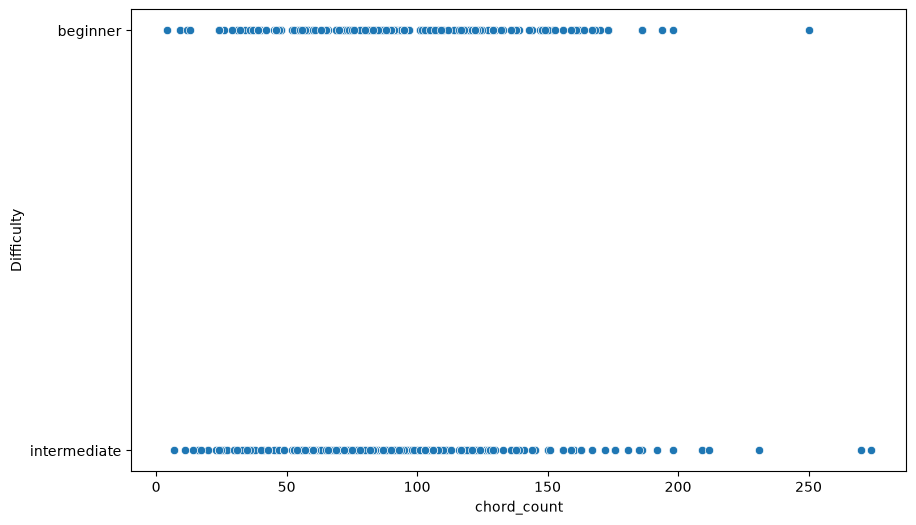

In [1134]:
plt.figure(figsize=(10,6))
sns.scatterplot(x=combined.chord_count, y=combined["Difficulty"])

Ok as I expected not much of a difference, lets look at unique chords instead

<Axes: xlabel='unique_chords', ylabel='Difficulty'>

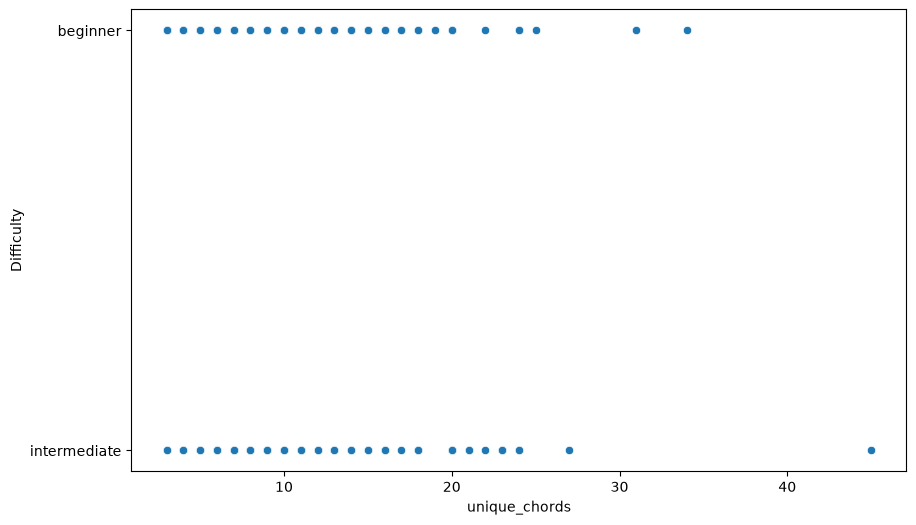

In [1135]:
plt.figure(figsize=(10,6))
sns.scatterplot(x=combined.unique_chords, y=combined["Difficulty"])

Still not much of a difference, this may also come with the small dataset but still, maybe there will be more differences when we look at characteristics

## Data Visualization: Complex Chords


<Axes: xlabel='unique_complex_chords', ylabel='Difficulty'>

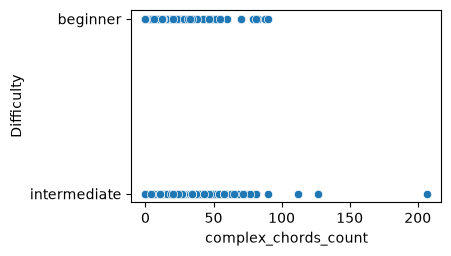

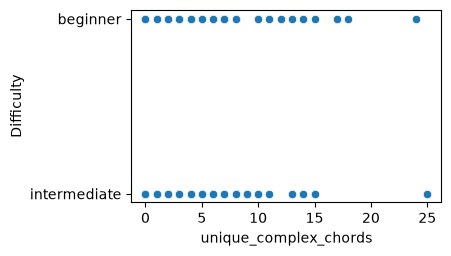

In [1138]:
# Count
plt.figure(figsize=(4,2.5))
sns.scatterplot(x=combined.complex_chords_count, y=combined["Difficulty"])

# Unique
plt.figure(figsize=(4,2.5))
sns.scatterplot(x=combined.unique_complex_chords, y=combined["Difficulty"])


Theres still very little difference

I'm interested in how the percentage will look

<Axes: xlabel='unique_complex_chords_pct', ylabel='Difficulty'>

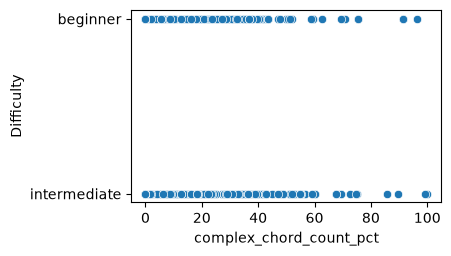

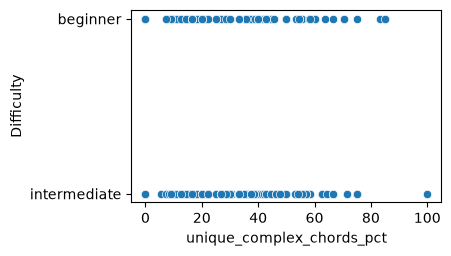

In [ ]:
# Count
plt.figure(figsize=(4,2.5))
sns.scatterplot(x=combined.complex_chord_count_pct, y=combined["Difficulty"])

# Unique
plt.figure(figsize=(4,2.5))
sns.scatterplot(x=combined.unique_complex_chords_pct, y=combined["Difficulty"])


Ok overall conclusion there is very little association between complex chords and difficulty of a song

## Data Visualization: Barre Chords
Keep in mind there is not a concrete way to determine whether a barre chord is used by just the name of the chord

<Axes: xlabel='unique_barre_chords', ylabel='Difficulty'>

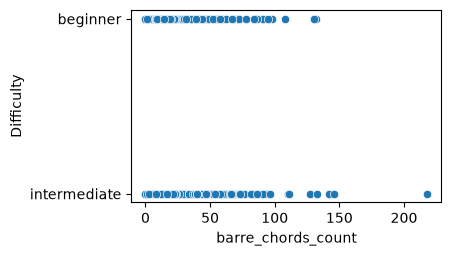

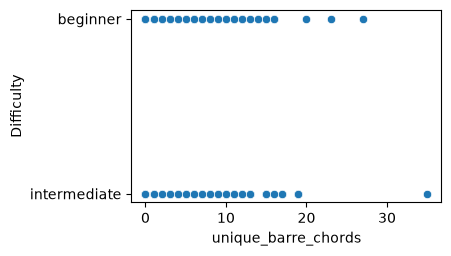

In [1140]:
# Count
plt.figure(figsize=(4,2.5))
sns.scatterplot(x=combined.barre_chords_count, y=combined["Difficulty"])

# Unique
plt.figure(figsize=(4,2.5))
sns.scatterplot(x=combined.unique_barre_chords , y=combined["Difficulty"])


Wow there is no correlation whatsoever, but also keep in mind this is a small portion of the already small dataset of top 850 chords
You can see that intermediate had more outliers

Lets look at the percentage

<Axes: xlabel='unique_barre_chords_pct', ylabel='Difficulty'>

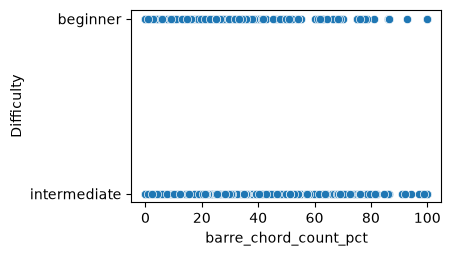

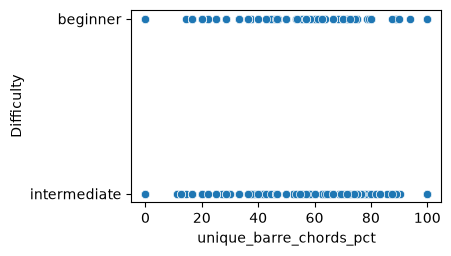

In [1142]:
# Count
plt.figure(figsize=(4,2.5))
sns.scatterplot(x=combined.barre_chord_count_pct, y=combined["Difficulty"])

# Unique
plt.figure(figsize=(4,2.5))
sns.scatterplot(x=combined.unique_barre_chords_pct , y=combined["Difficulty"])


## Overall Conclusions
